# Dataset Pipline
 goal: Prepare historical student data for the Academic Early Warning System.

  ** Outlines: **

 * Clean dataset
 * Engineered features
 * Train/Validation/Test splits
 * Leakage validation report

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
RANDOM_STATE = 42
# step 2: Load Dataset and transform to Dataframe structure 

df = pd.read_csv("synthetic_student_data.csv")

print(df.shape)



(212, 14)


In [ ]:
# Initial Data Inspection Statistical Summary
RAW_DATA = Path("synthetic_student_data.csv")
Cleaned_sythetic_Stu = Path("Cleaned_synthetic_stu_Data.csv")
ARTIFACTS_DIR = Path("/model/registry")
REPORTS_DIR = Path("data_quality")

for directory in [Cleaned_sythetic_Stu, ARTIFACTS_DIR, REPORTS_DIR]:
    if directory.suffix.lower() == ".csv":
        directory.parent.mkdir(parents=True, exist_ok=True)
    else:
        directory.mkdir(parents=True, exist_ok=True)
        
# Columns that must never enter the model because they are future outcomes,
# direct target proxies, administrative decisions, or identifiers.
LEAKAGE_COLUMNS = [
    "Course Outcomes",
    "Semester GPA",
    "Cumulative GPA",
    "Progression Status",
    "Credits Completed",
    
]
ID_COLUMN = "anonymous_student_identifier"
# TARGET_COLUMN = "Academic risk"

# Use these for chronological splitting when available.
# Examples: "academic_year", "semester_order", or "term_start_date" TIME_COLUMN = "Academic Term"


# If TARGET_COLUMN does not exist, optionally derive it from an end-of-term outcome.
# This source column will be used ONLY to form y, and then removed from X.
df["Academic risk"] = df["Progression Status"].isin(
    ["Academic Warning", "Probation"]
).astype(int)
TARGET_COLUMN = "Academic risk"
TIME_COLUMN = "Academic Term"


# Optional manual exclusions (free text, duplicate IDs, unusable fields, etc.)
EXCLUDED_COLUMNS = []

print("Configuration loaded.")

df.info()
df.describe(include="all")

Configuration loaded.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Anonymous Student Identifier  212 non-null    object 
 1   Program                       212 non-null    object 
 2   Academic Term                 212 non-null    object 
 3   Course Attempts               212 non-null    int64  
 4   Credits Attempted             212 non-null    int64  
 5   Credits Completed             212 non-null    int64  
 6   Course Outcomes               212 non-null    object 
 7   Semester GPA                  212 non-null    float64
 8   Cumulative GPA                212 non-null    float64
 9   Withdrawals                   212 non-null    int64  
 10  Repeated Courses              212 non-null    int64  
 11  Progression Status            212 non-null    object 
 12  Attendance                    102 non-null

,Anonymous Student Identifier,Program,Academic Term,Course Attempts,Credits Attempted,Credits Completed,Course Outcomes,Semester GPA,Cumulative GPA,Withdrawals,Repeated Courses,Progression Status,Attendance,Early Assessment Results,Academic risk
count,212,212,212,212.000000,212.000000,212.000000,212,212.000000,212.000000,212.000000,212.000000,212,102,82,212.000000
unique,100,5,3,NaN,NaN,NaN,212,NaN,NaN,NaN,NaN,3,27,3,NaN
top,STU_0002,Business Administration,2025-Fall,NaN,NaN,NaN,"CRSE-121: 2.0, CRSE-352: 2.4, CRSE-335: 1.6, C...",NaN,NaN,NaN,NaN,Good Standing,100%,Pass,NaN
freq,3,55,100,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,182,22,45,NaN
mean,NaN,NaN,NaN,3.962264,11.886792,11.292453,NaN,2.741981,2.740802,0.198113,0.094340,NaN,NaN,NaN,0.141509
std,NaN,NaN,NaN,0.853479,2.560438,2.863289,NaN,0.744768,0.642960,0.494899,0.292992,NaN,NaN,NaN,0.349371
min,NaN,NaN,NaN,3.000000,9.000000,3.000000,NaN,0.960000,1.100000,0.000000,0.000000,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,3.000000,9.000000,9.000000,NaN,2.170000,2.280000,0.000000,0.000000,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,4.000000,12.000000,12.000000,NaN,2.750000,2.780000,0.000000,0.000000,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,5.000000,15.000000,15.000000,NaN,3.360000,3.232500,0.000000,0.000000,NaN,NaN,NaN,0.000000


In [ ]:

if "raw_df" not in globals():
    if "RAW_DATA_PATH" not in globals():
        RAW_DATA_PATH = Path("synthetic_student_data.csv")
    if not RAW_DATA_PATH.exists():
        raise FileNotFoundError(f"Dataset not found: {RAW_DATA_PATH.resolve()}")
    def audit_dataframe(df: pd.DataFrame) -> pd.DataFrame:
        audit = pd.DataFrame({
            "Col_name": df.columns,
            "DType": [str(df[c].dtype) for c in df.columns],
            "count_missing": [int(df[c].isna().sum()) for c in df.columns],
            "missing_pct": [round(df[c].isna().mean() * 100, 2) for c in df.columns],
            "count_unique": [int(df[c].nunique(dropna=True)) for c in df.columns],
        })
        return audit.sort_values(["missing_pct", "Col_name"], ascending=[False, True])

    if "raw_df" not in globals():
        if "RAW_DATA_PATH" not in globals():
            RAW_DATA_PATH = Path("synthetic_student_data.csv")
        if not RAW_DATA_PATH.exists():
            raise FileNotFoundError(f"Dataset not found: {RAW_DATA_PATH.resolve()}")
        raw_df = pd.read_csv(RAW_DATA_PATH)

    if "REPORTS_DIR" not in globals():
        REPORTS_DIR = Path("model/data_quality")
    REPORTS_DIR.mkdir(parents=True, exist_ok=True)


    initial_audit = audit_dataframe(raw_df)
    print(f"Duplicate rows: {raw_df.duplicated().sum():,}")
    display(initial_audit)
    initial_audit.to_csv(REPORTS_DIR / "initial_data_audit.csv", index=False)
   

Duplicate rows: 0


,Col_name,DType,count_missing,missing_pct,count_unique
13,Early Assessment Results,object,130,61.32,3
12,Attendance,object,110,51.89,27
2,Academic Term,object,0,0.00,3
0,Anonymous Student Identifier,object,0,0.00,100
3,Course Attempts,int64,0,0.00,3
6,Course Outcomes,object,0,0.00,212
4,Credits Attempted,int64,0,0.00,3
5,Credits Completed,int64,0,0.00,5
8,Cumulative GPA,float64,0,0.00,153
1,Program,object,0,0.00,5


In [4]:
# Remove Duplicate Records Handle Missing Values 

df = df.drop_duplicates().copy()
print("Sum of Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().copy()

# Fill missing numeric values with each column's median
numerical_cols = df.select_dtypes(include="number").columns
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after numeric imputation:")
print(df[numerical_cols].isna().sum())

# Keep missing Early Assessment Results unchanged; it is categorical.

# Fill missing numeric values with their medians
numerical_cols2 = [
   # "Semester GPA","Cumulative GPA", "Credits Completed",
   "Attendance",
   "Early Assessment Results"
]

# Convert values such as "95%" to numeric values before filling missing entries
attendance_col = next(
    (c for c in df.columns if c.lower() == "attendance"),
    None
)
if attendance_col is None:
    raise KeyError(
        f"Attendance column not found. Available columns: {list(df.columns)}"
    )

df[attendance_col] = pd.to_numeric(
    df[attendance_col].astype("string").str.replace("%", "", regex=False).str.strip(),
    errors="coerce"
)
# df[attendance_col] = df[attendance_col].fillna(df[attendance_col].median())
Avg_attendance = (df.isna().mean() * 100).round(1)
 
print(f"Average of attendance = {Avg_attendance}")

Sum of Duplicates: 0
Missing values after numeric imputation:
Course Attempts      0
Credits Attempted    0
Credits Completed    0
Semester GPA         0
Cumulative GPA       0
Withdrawals          0
Repeated Courses     0
Academic risk        0
dtype: int64
Average of attendance = Anonymous Student Identifier     0.0
Program                          0.0
Academic Term                    0.0
Course Attempts                  0.0
Credits Attempted                0.0
Credits Completed                0.0
Course Outcomes                  0.0
Semester GPA                     0.0
Cumulative GPA                   0.0
Withdrawals                      0.0
Repeated Courses                 0.0
Progression Status               0.0
Attendance                      51.9
Early Assessment Results        61.3
Academic risk                    0.0
dtype: float64


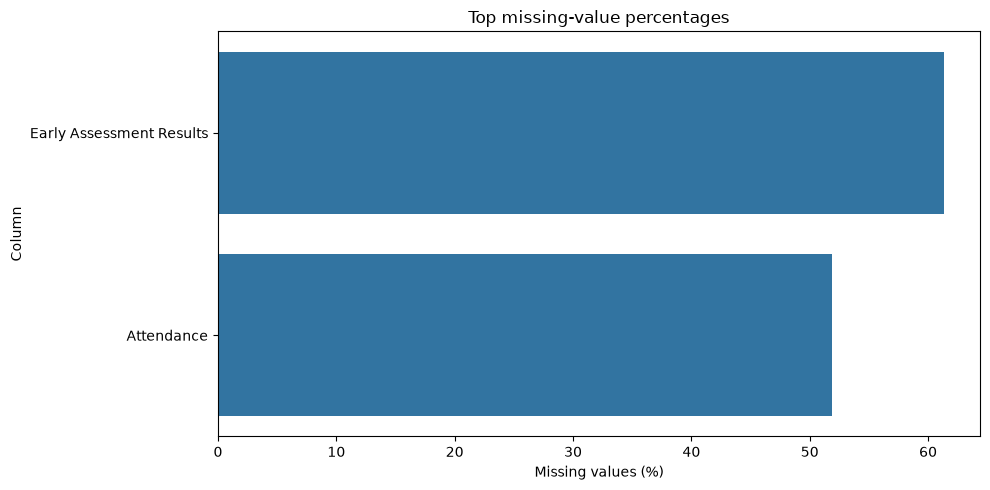

In [5]:
# Missingness chart for columns that contain missing values
missing_plot = (
    initial_audit.loc[initial_audit["count_missing"] > 0, ["Col_name", "missing_pct"]]
    .rename(columns={"Col_name": "column"})
    .head(25)
)
if not missing_plot.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(data=missing_plot, x="missing_pct", y="column")
    plt.title("Top missing-value percentages")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")


In [6]:
df = raw_df.copy()
# Standardize column names
original_columns = df.columns.tolist()
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

if len(set(df.columns)) != len(df.columns):
    raise ValueError("Duplicate column names appeared after standardization. Rename them in the source data.")

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Validate ID when supplied
if ID_COLUMN in df.columns:
    missing_ids = int(df[ID_COLUMN].isna().sum())
    if missing_ids:
        print(f"Warning: dropping {missing_ids:,} rows with missing {ID_COLUMN}.")
        df = df.dropna(subset=[ID_COLUMN]).copy()
else:
    print(f"Warning: ID column '{ID_COLUMN}' was not found.")

# Parse chronological field if present
if TIME_COLUMN in df.columns:
    parsed_time = pd.to_datetime(df[TIME_COLUMN], errors="coerce")
    if parsed_time.notna().mean() >= 0.80:
        df[TIME_COLUMN] = parsed_time
    else:
        print(f"Warning: '{TIME_COLUMN}' could not be reliably parsed as dates; original values kept.")

print(f"Cleaned shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

Cleaned shape: 212 rows x 14 columns


In [11]:
# Create the binary target if it is not already present
TARGET_COLUMN = "academic_risk"

if TARGET_COLUMN not in df.columns:
    df[TARGET_COLUMN] = df["progression_status"].isin(
        ["Academic Warning", "Probation"]
    ).astype(int)

before = len(df)
df = df.dropna(subset=[TARGET_COLUMN]).copy()

unexpected = sorted(set(df[TARGET_COLUMN].unique()) - {0, 1})
if unexpected:
    raise ValueError(f"Target must be binary 0/1. Unexpected values: {unexpected}")

print(f"Rows removed because target was missing: {before - len(df):,}")

target_summary = pd.DataFrame({
    "metric": [
        "unique_students",
        "unique_terms",
        "risk_percentage",
    ],
    "value": [
        df["anonymous_student_identifier"].nunique(),
        df["academic_term"].nunique(),
        round(df[TARGET_COLUMN].mean() * 100, 2),
    ],
})

display(target_summary)


Rows removed because target was missing: 0


,metric,value
0,unique_students,100.00
1,unique_terms,3.00
2,risk_percentage,14.15


# Leakage guard and feature selection

Review `LEAKAGE_COLUMNS` with the feature dictionary. A feature may be valid in one prediction window and leakage in another. For example, Week 8 attendance cannot be used for a Week 4 prediction.

In [14]:
LEAKAGE_COLUMNS = [
    "course_outcomes",
    "semester_gpa",
    "cumulative_gpa",
    "progression_status",
    "credits_completed"
]
 
BLOCKED_COLUMNS = [
    "academic_risk",
    "anonymous_student_identifier"
] + LEAKAGE_COLUMNS
 
X = df.drop(columns=BLOCKED_COLUMNS, errors="ignore")
y = df["academic_risk"]
 
print("Columns blocked from predictors:")
print(BLOCKED_COLUMNS)
 
print("\nColumns used as predictors:")
print(X.columns.tolist())

Columns blocked from predictors:
['academic_risk', 'anonymous_student_identifier', 'course_outcomes', 'semester_gpa', 'cumulative_gpa', 'progression_status', 'credits_completed']

Columns used as predictors:
['program', 'academic_term', 'course_attempts', 'credits_attempted', 'withdrawals', 'repeated_courses', 'attendance', 'early_assessment_results']


In [25]:
# Define Target Variable ** Academic Risk Flag **
 
# Students are considered "at risk" when their progression status
# is Academic Warning or Probation.
 
df["academic_risk"] = df["progression_status"].isin(
    ["Academic Warning", "Probation"]
).astype(int)
 
# Check class balance
print("Academic risk distribution:")
print(df["academic_risk"].value_counts())
 
print("\nAcademic risk percentage:")
print((df["academic_risk"].value_counts(normalize=True) * 100).round(2))
 
# Check risk distribution by academic term and program
print("\nProportion by academic term, program, and risk status:")
print(
    df[["academic_term", "program", "academic_risk"]]
    .value_counts(normalize=True)
)

Academic risk distribution:
academic_risk
0    182
1     30
Name: count, dtype: int64

Academic risk percentage:
academic_risk
0    85.85
1    14.15
Name: proportion, dtype: float64

Proportion by academic term, program, and risk status:
academic_term  program                  academic_risk
2025-Fall      Mechanical Engineering   0                0.089623
               Business Administration  0                0.084906
               Computer Science         0                0.080189
2026-Spring    Mechanical Engineering   0                0.075472
               Business Administration  0                0.070755
2026-Fall      Business Administration  0                0.061321
2026-Spring    Computer Science         0                0.056604
2025-Fall      Psychology               0                0.056604
               Nursing                  0                0.056604
2026-Spring    Nursing                  0                0.056604
2026-Fall      Mechanical Engineering   0       

# Feature Engineering

  * Credit Completion Ratio
  * Repeated Courses Indicator
  * Withdrawal Indicator


In [32]:
# Feature Engineering
 
# Repeated courses flag

df["has_repeated_courses"] = (df["repeated_courses"] > 0).astype(int)
 
# Withdrawals flag

df["has_withdrawals"] = (df["withdrawals"] > 0).astype(int)
 
# Preview engineered features

featured_eng = df[

    [
        "has_repeated_courses",
        "has_withdrawals"
    ]

].copy()
 
print("Engineered Features:")

display(featured_eng.head())
 
print("\nCount of withdrawals by academic term:")

print(

    pd.crosstab(

        df["academic_term"],

        df["has_withdrawals"]

    )
)
 


Engineered Features:


,has_repeated_courses,has_withdrawals
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0



Count of withdrawals by academic term:
has_withdrawals   0   1
academic_term          
2025-Fall        87  13
2026-Fall        34   7
2026-Spring      58  13


In [34]:
# Save the cleaned dataset in new Cleaned_synthetic_stu_Data.csv 
df.to_csv(
    "Cleaned_synthetic_stu_Data.csv",
    index=False
)

print("Clean dataset Successfully saved!")

Clean dataset Successfully saved!
